=== PRAKTIKUM 1: EKSPERIMEN PARAMETER PRE-PRUNING ===
max_depth=2, min_samples_leaf=1 : akurasi test=0.930
max_depth=2, min_samples_leaf=5 : akurasi test=0.930
max_depth=2, min_samples_leaf=10 : akurasi test=0.930
max_depth=4, min_samples_leaf=1 : akurasi test=0.947
max_depth=4, min_samples_leaf=5 : akurasi test=0.947
max_depth=4, min_samples_leaf=10 : akurasi test=0.947
max_depth=6, min_samples_leaf=1 : akurasi test=0.939
max_depth=6, min_samples_leaf=5 : akurasi test=0.956
max_depth=6, min_samples_leaf=10 : akurasi test=0.947
max_depth=None, min_samples_leaf=1 : akurasi test=0.947
max_depth=None, min_samples_leaf=5 : akurasi test=0.956
max_depth=None, min_samples_leaf=10 : akurasi test=0.947

=== PRAKTIKUM 2: COST COMPLEXITY PRUNING PATH (POST-PRUNING) ===


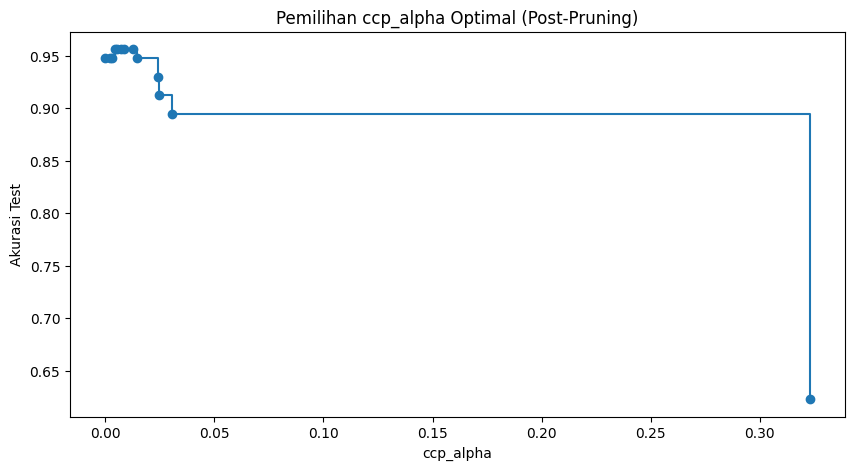

Nilai ccp_alpha optimal terbaik: 0.00431 dengan akurasi: 0.956


In [12]:
# ==========================================
# PRAKTIKUM BAB 5: PRUNING (DECISION TREE)
# ==========================================

import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Load dataset untuk contoh praktikum
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("=== PRAKTIKUM 1: EKSPERIMEN PARAMETER PRE-PRUNING ===")
# Praktikum 5.7: Eksperimen Pre-Pruning dengan kombinasi max_depth dan min_samples_leaf
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=42
        )
        model.fit(X_train, y_train)
        acc = accuracy_score(y_test, model.predict(X_test))
        print(f"max_depth={depth}, min_samples_leaf={min_leaf} : akurasi test={acc:.3f}")

print("\n=== PRAKTIKUM 2: COST COMPLEXITY PRUNING PATH (POST-PRUNING) ===")
# Latih model penuh terlebih dahulu untuk mendapatkan path ccp_alpha
model_full = DecisionTreeClassifier(random_state=42)
model_full.fit(X_train, y_train)

# Praktikum 5.8: Cost Complexity Pruning Path
path = model_full.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas
akurasi_test = []

for alpha in ccp_alphas:
    m = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    m.fit(X_train, y_train)
    akurasi_test.append(accuracy_score(y_test, m.predict(X_test)))

# Visualisasi Kurva CCP Alpha
plt.figure(figsize=(10, 5))
plt.plot(ccp_alphas, akurasi_test, marker='o', drawstyle="steps-post")
plt.xlabel("ccp_alpha")
plt.ylabel("Akurasi Test")
plt.title("Pemilihan ccp_alpha Optimal (Post-Pruning)")
plt.show()

# Menentukan ccp_alpha dengan akurasi test tertinggi
best_alpha_idx = akurasi_test.index(max(akurasi_test))
best_alpha = ccp_alphas[best_alpha_idx]
print(f"Nilai ccp_alpha optimal terbaik: {best_alpha:.5f} dengan akurasi: {max(akurasi_test):.3f}")